# Tier 1 — Cardiovascular risk screening from a basic medical exam

**Project:** Cardiovascular Risk Prediction and Diagnosis Using Machine Learning (Data Science II, USCO).
**Dataset:** Kaggle *Cardiovascular Disease dataset* (S. Ulianova, 2019), 70,000 patients, 11 exam variables.

This notebook runs the whole tier step by step. Every cleaning step, figure, table, metric and model
is recorded automatically in `outputs/clinical/` (see `TRACEABILITY.md` and `run_manifest.json`).

| Rubric criterion (Hito 2) | Where |
|---|---|
| Dataset construction (balanced, > 35,000 records) | Sections 2–3 |
| Selection of 4 ML models | Sections 5–6 |
| Results simulation with traceability | Sections 9–10 |
| Mathematical model (equations + graphs) | `docs/mathematical_model.md` + all figures |

In [1]:
# --- Setup -------------------------------------------------------------
# Local: run from ml-pipeline/notebooks with the project's virtual environment.
# Google Colab: uncomment the next three lines (replace <repo-url>).
# !git clone <repo-url> repo
# %cd repo/ml-pipeline/notebooks
# !pip install -q -r ../requirements.txt
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
%matplotlib inline
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
from cardio_ml import config
from cardio_ml.workflows import ClinicalRiskWorkflow
wf = ClinicalRiskWorkflow(show=True)

## 1. Extraction
The raw CSV (`;` separator) is read and its SHA-256 checksum is stored, so any later change to the source file is detectable.

In [2]:
wf.ingest()
wf.raw.head()

[clinical] Load raw CSV: 70,000 -> 70,000 rows. 13 columns, separator ';'


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## 2. Transformation: cleaning, feature engineering and balancing

Rules applied (and logged with the number of rows each one removes):
1. Drop the `id` column, then exact duplicates, then contradictory records (same features, different diagnosis).
2. Remove physiologically impossible values: SBP outside 80–250 mmHg, DBP outside 40–160, SBP ≤ DBP, height outside 130–210 cm, weight outside 35–200 kg, BMI outside 13–60.
3. Derive `age_years`, `bmi`, `map`, `pulse_pressure` and the AHA 2017 `bp_stage`.
4. Balance the classes 50/50 by random undersampling.

In [3]:
wf.clean()
wf.tracker.lineage_frame()

[clinical] Drop identifier columns: 70,000 -> 70,000 rows. dropped ['id'] (no predictive meaning)
[clinical] Remove duplicated records: 70,000 -> 69,976 rows. identical rows (all features and label) kept once
[clinical] Remove contradictory records: 69,976 -> 69,942 rows. same feature values with different diagnosis
[clinical] Filter impossible blood pressure: 69,942 -> 68,688 rows. ap_hi outside [80, 250]: 247; ap_lo outside [40, 160]: 1007
[clinical] Check systolic > diastolic: 68,688 -> 68,606 rows. systolic pressure must exceed diastolic pressure
[clinical] Filter impossible height/weight: 68,606 -> 68,501 rows. height outside [130, 210]: 89; weight outside [35, 200]: 16
[clinical] Convert age from days to years: 68,501 -> 68,501 rows. age_years = age_days / 365.25
[clinical] Engineer clinical features: 68,501 -> 68,501 rows. added bmi, map, pulse_pressure, bp_stage (AHA 2017)
[clinical] Filter implausible BMI: 68,501 -> 68,480 rows. bmi outside [13, 60]: 21
[clinical] Balance clas

,step,rows_before,rows_after,detail,removed
0,Load raw CSV,70000,70000,"13 columns, separator ';'",0
1,Drop identifier columns,70000,70000,dropped ['id'] (no predictive meaning),0
2,Remove duplicated records,70000,69976,identical rows (all features and label) kept once,24
3,Remove contradictory records,69976,69942,same feature values with different diagnosis,34
4,Filter impossible blood pressure,69942,68688,"ap_hi outside [80, 250]: 247; ap_lo outside [4...",1254
5,Check systolic > diastolic,68688,68606,systolic pressure must exceed diastolic pressure,82
6,Filter impossible height/weight,68606,68501,"height outside [130, 210]: 89; weight outside ...",105
7,Convert age from days to years,68501,68501,age_years = age_days / 365.25,0
8,Engineer clinical features,68501,68501,"added bmi, map, pulse_pressure, bp_stage (AHA ...",0
9,Filter implausible BMI,68501,68480,"bmi outside [13, 60]: 21",21


## 3. Exploratory data analysis (INFOVIZ)

Univariate (histogram + KDE, IQR boxplots), bivariate (split violins, scatter, prevalence by factor),
multivariate (pairplot, PCA), Pearson vs. Spearman triangular heatmaps and a multicollinearity check (VIF).
The VIF check removes `map`, `pulse_pressure` and `weight` from the model inputs.

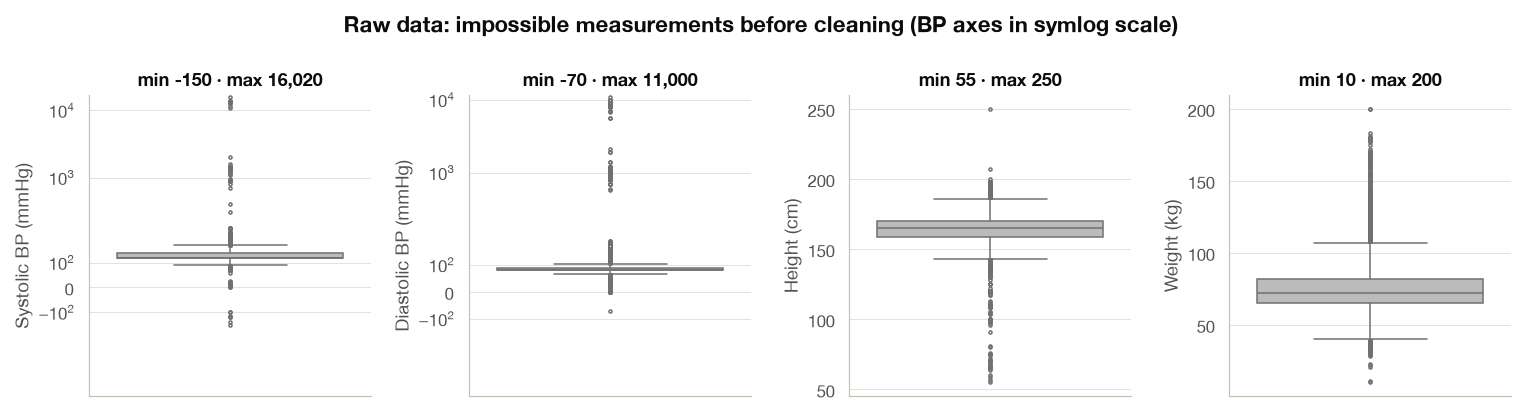

> **Figure 1 — Raw measurements: impossible blood pressures, heights and weights**  
> *What it shows:* Boxplots of blood pressure, height and weight exactly as they come in the source file, before cleaning.  
> *How to read it:* Points far from the box are impossible values (e.g. pressures of thousands of mmHg or negative). They justify the physiological range filters.

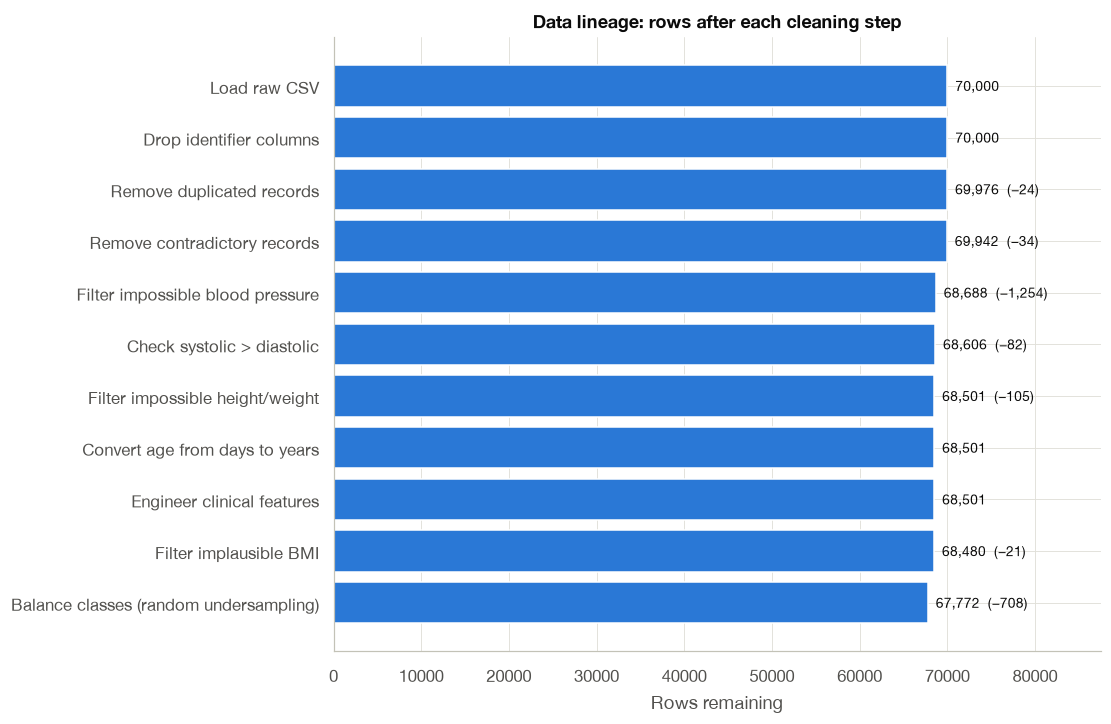

> **Figure 2 — Rows remaining after each cleaning step**  
> *What it shows:* Each bar is the dataset after one cleaning step; in brackets, how many rows that step removed.  
> *How to read it:* Read it top to bottom. No row disappears without a reason: each step is explained in TRACEABILITY.md.

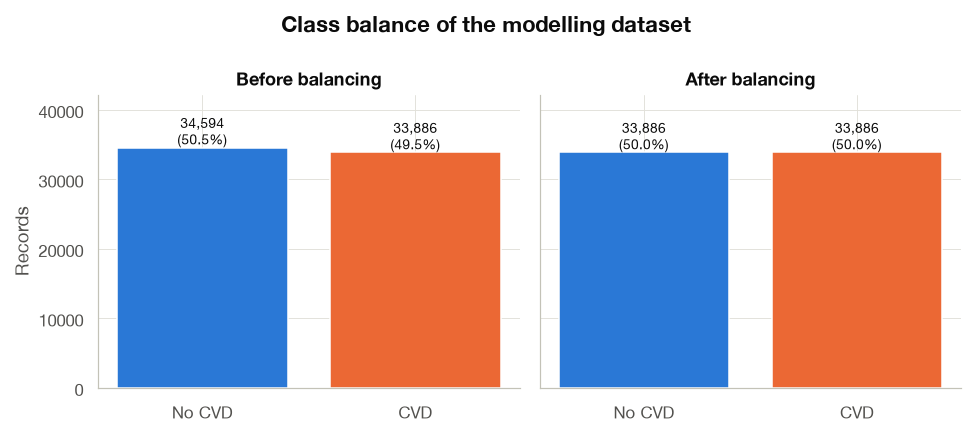

> **Figure 3 — Class balance before and after undersampling**  
> *What it shows:* How many cases of each class there are. All cases of the rarer class are kept and the same number is drawn at random from the common one (undersampling).  
> *How to read it:* On the right both bars must be equal (50/50). Accuracy cannot then be inflated by always answering the common class.

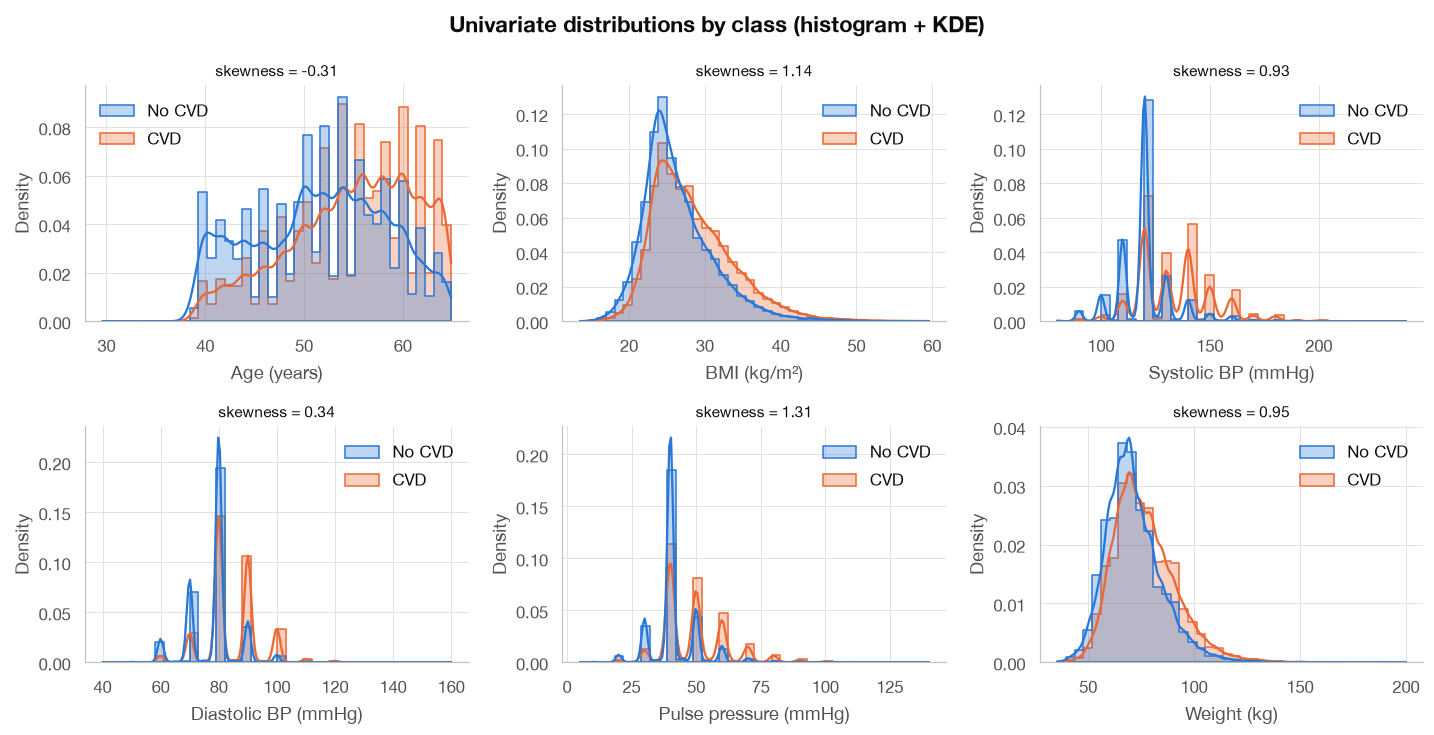

> **Figure 4 — Histograms and KDE of the numeric variables by diagnosis**  
> *What it shows:* Histogram with its smoothed curve (KDE) for each variable, one colour per class. Above, the skewness.  
> *How to read it:* If the two curves are apart, the variable helps to tell the classes apart; if they overlap, it adds little.

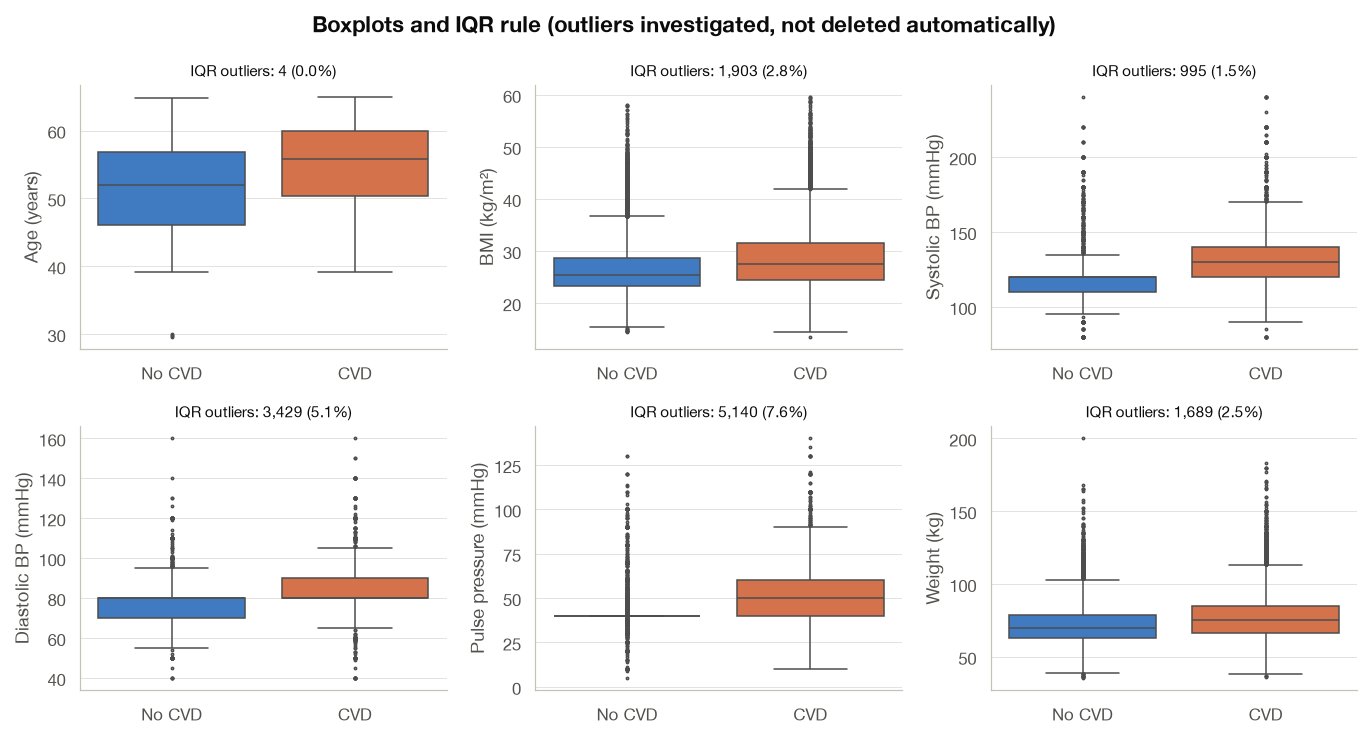

> **Figure 5 — Boxplots with the IQR outlier rule by diagnosis**  
> *What it shows:* Boxes per class. Anything outside Q1 − 1.5·IQR or Q3 + 1.5·IQR is flagged as an outlier.  
> *How to read it:* The line is the median. A higher box in the sick group points to a risk factor. Outliers are reviewed, not deleted automatically.

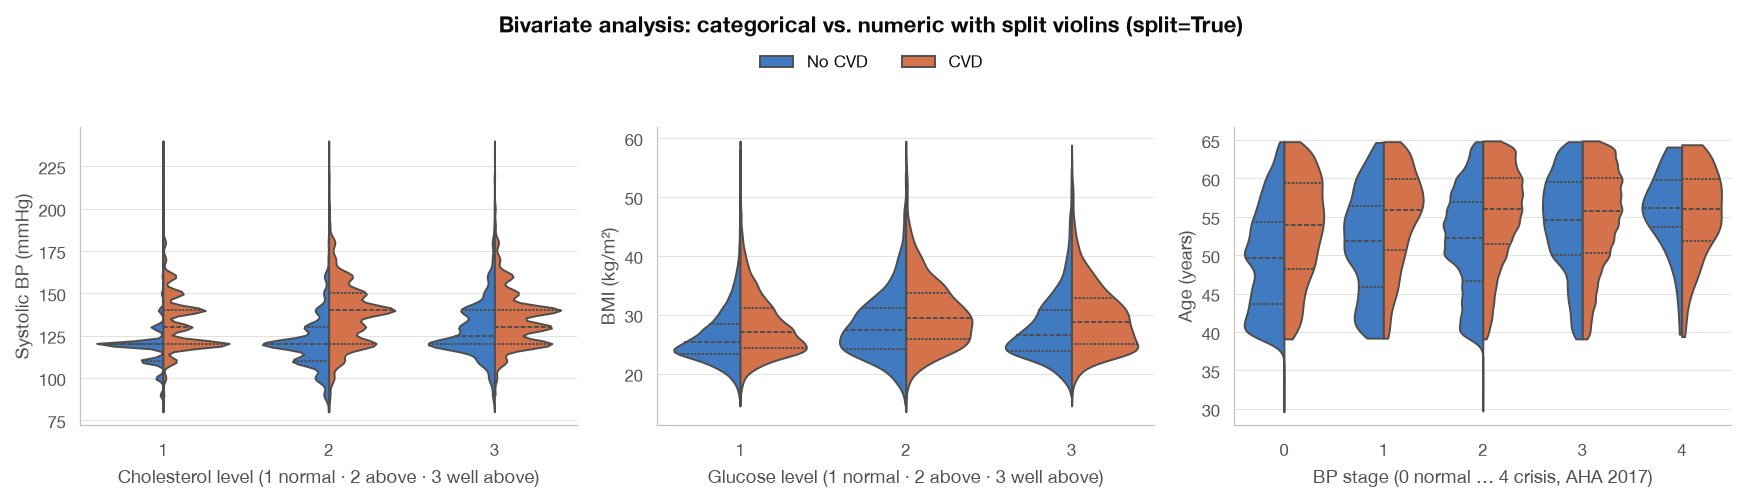

> **Figure 6 — Split violin plots: categorical factors vs. numeric variables**  
> *What it shows:* Each violin is the shape of the distribution; the left half is one class and the right half the other.  
> *How to read it:* When the right half (CVD) sits higher, the variable is higher in sick people.

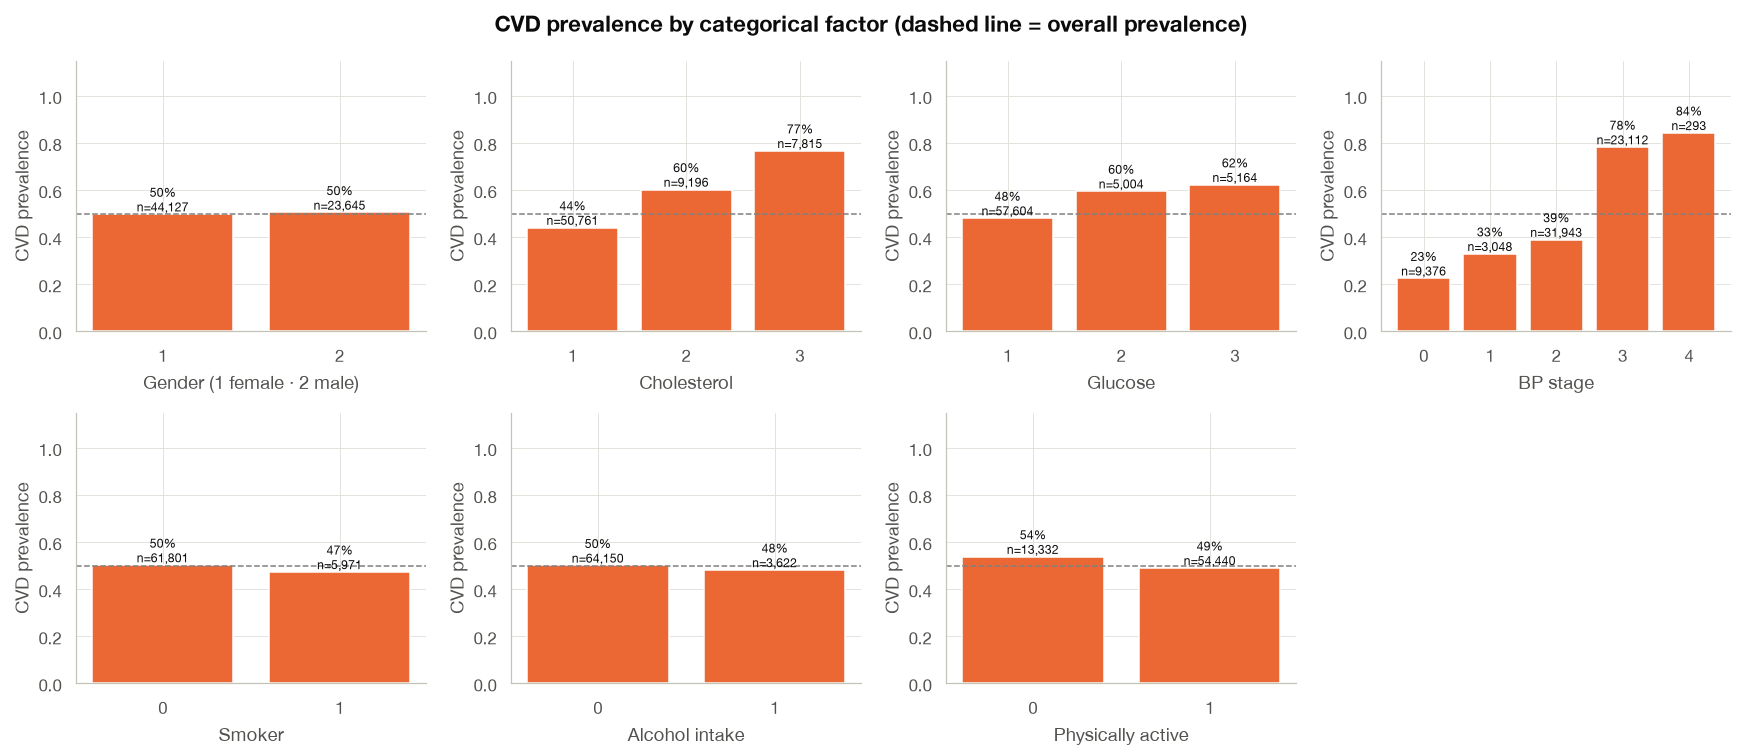

> **Figure 7 — CVD prevalence by categorical factor**  
> *What it shows:* Prevalence = sick people in the group ÷ people in the group, for every level of every factor.  
> *How to read it:* Bars above the dashed line (overall average) mark risk factors. In this dataset smoking and glucose go the opposite way to medicine: a known bias of the data, which is why the model has clinical constraints.

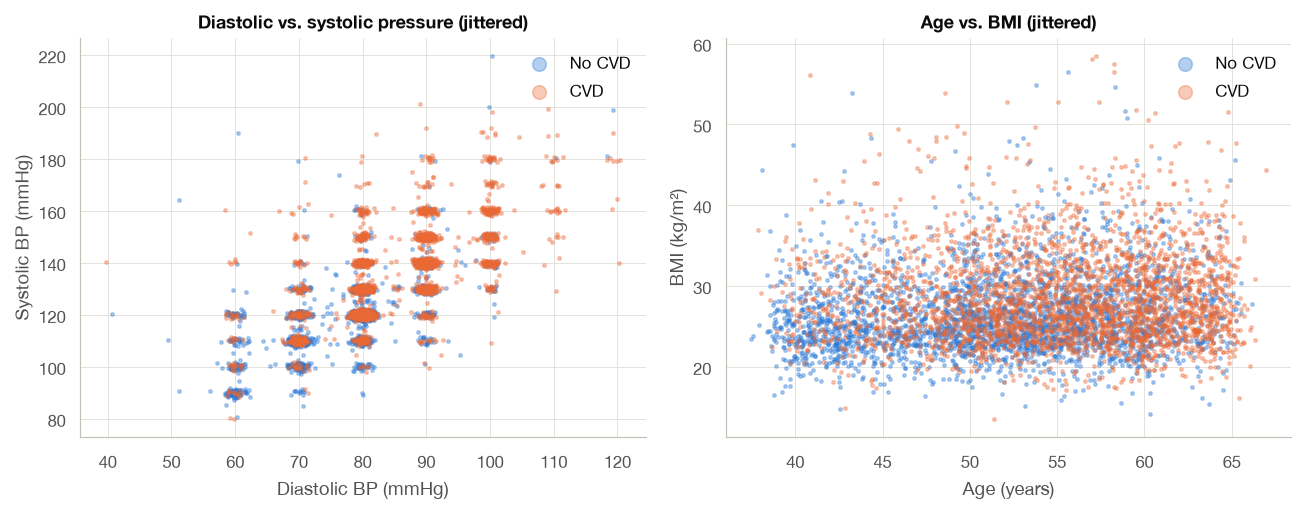

> **Figure 8 — Scatter plots of blood pressure and age vs. BMI**  
> *What it shows:* Each dot is a patient, coloured by diagnosis.  
> *How to read it:* Areas where one colour dominates show value combinations linked to the disease.

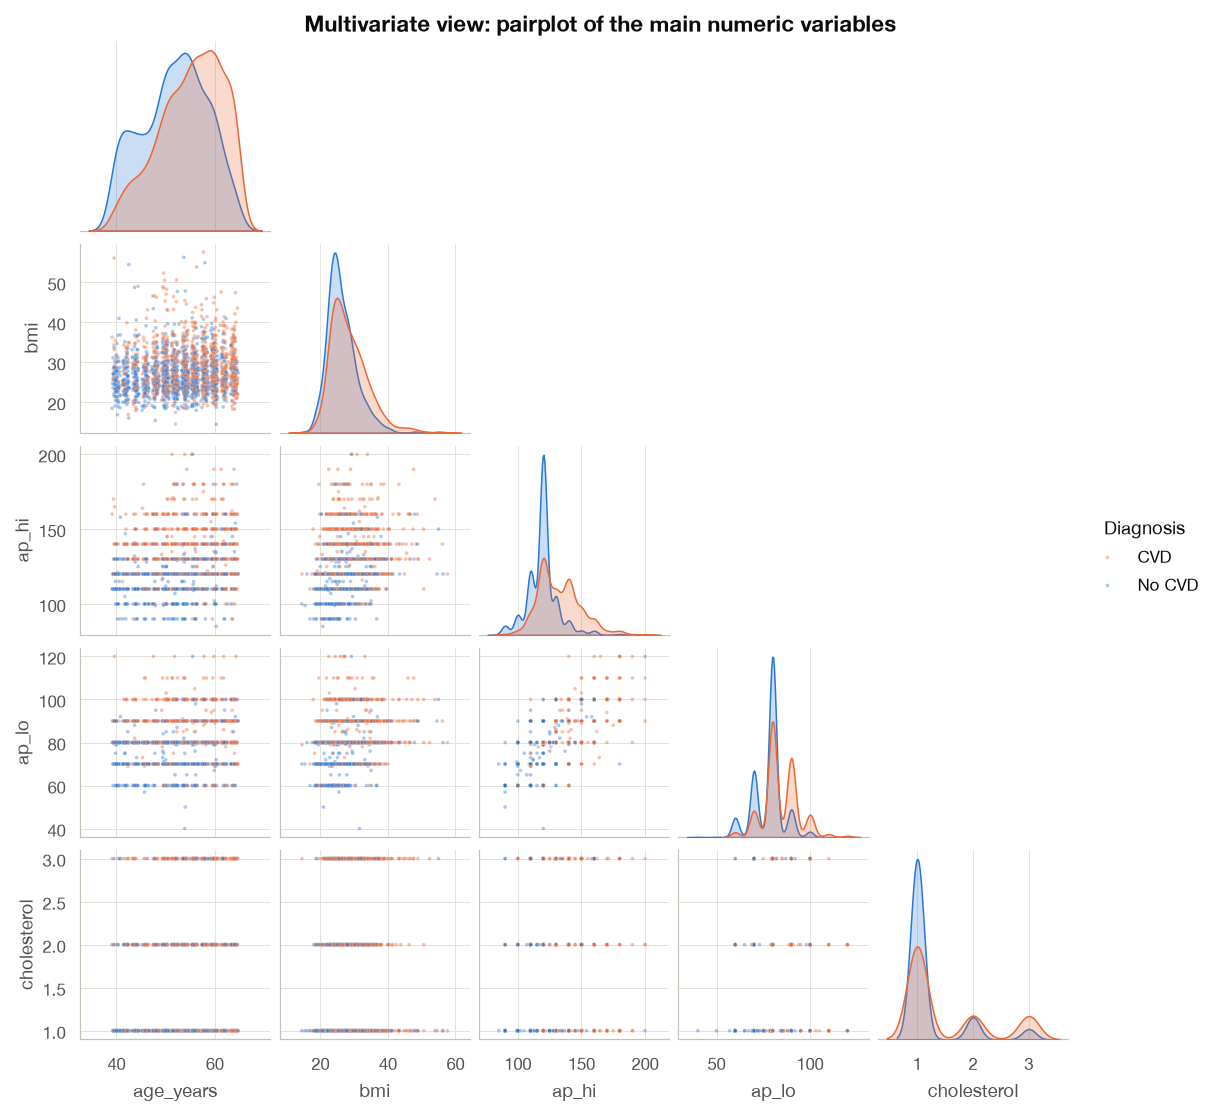

> **Figure 9 — Pairplot of the main numeric variables**  
> *What it shows:* Grid of scatter plots between pairs of variables; on the diagonal, each variable's distribution.  
> *How to read it:* Shows at a glance how variables relate and whether any of them separates the classes.

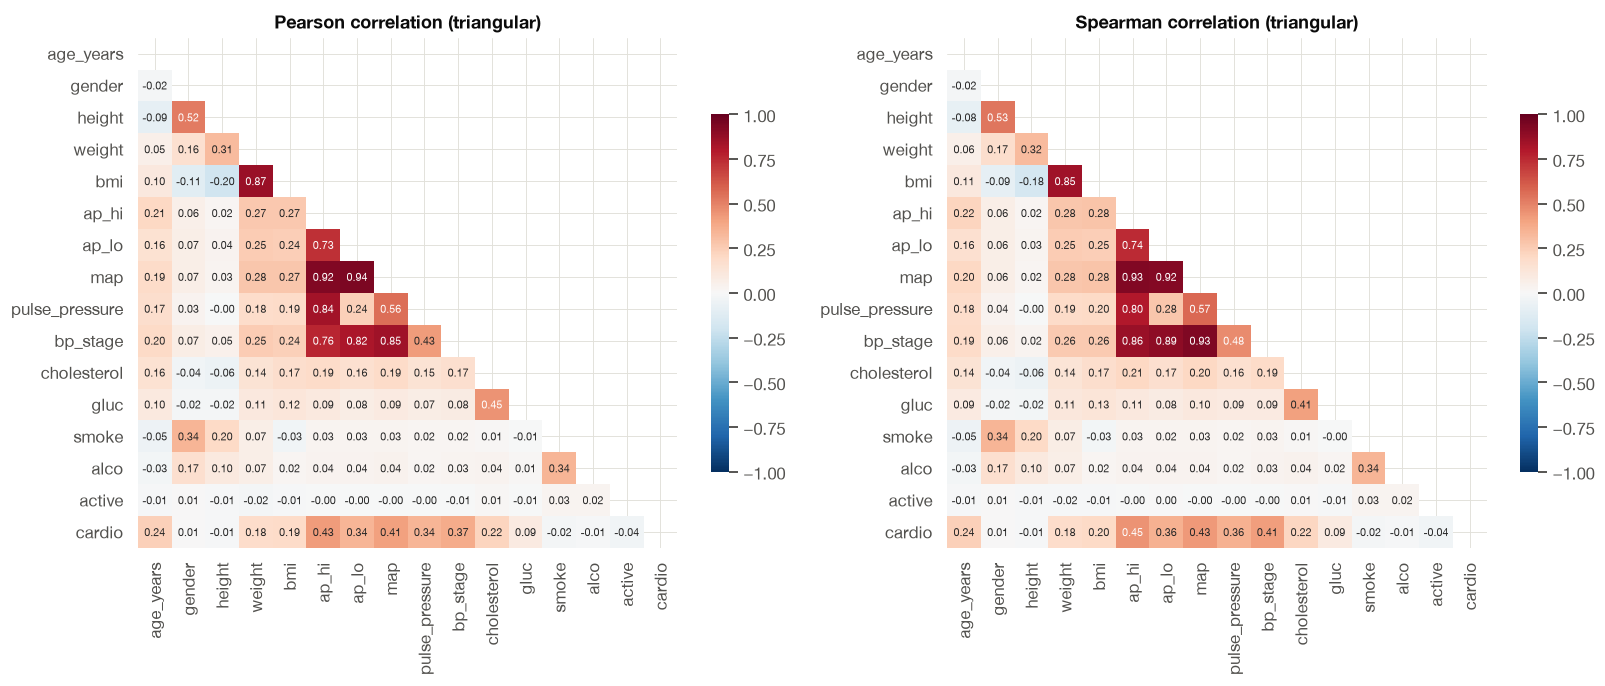

> **Figure 10 — Pearson vs. Spearman correlation matrices (triangular)**  
> *What it shows:* Pearson measures linear association; Spearman, ordered association (uses ranks, robust to outliers). From −1 to 1.  
> *How to read it:* Red: they rise together. Blue: one rises as the other falls. White: no relation. Look at the target's row.

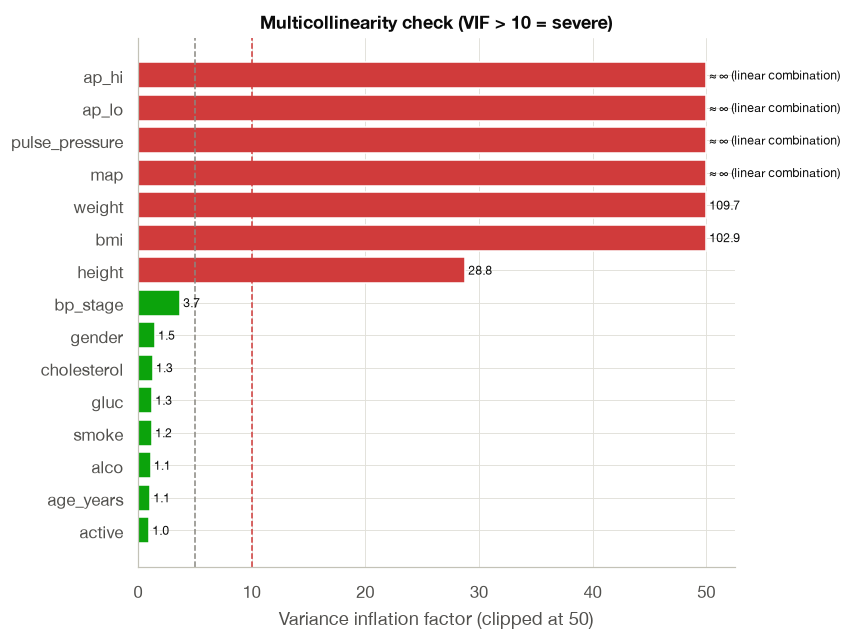

> **Figure 11 — Multicollinearity of the candidate features (VIF)**  
> *What it shows:* VIF = 1 / (1 − R²): how well one variable can be predicted from the others.  
> *How to read it:* Green < 5 fine, yellow 5–10 moderate, red > 10 severe. Variables with infinite VIF are copies of others and are removed from the model.

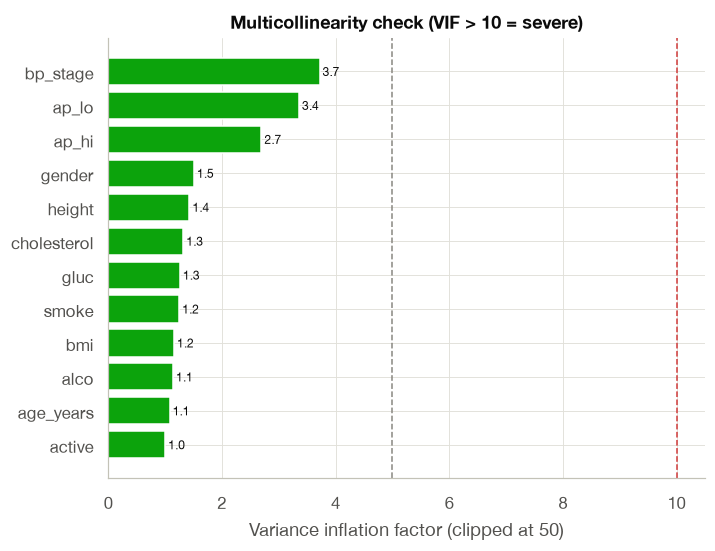

> **Figure 12 — VIF after dropping ['map', 'pulse_pressure', 'weight'] (exact linear combinations)**  
> *What it shows:* The same VIF computation with the variables the model really uses.  
> *How to read it:* All bars should now be green or yellow: no duplicated information is left.

[clinical] NOTE: Dropped ['map', 'pulse_pressure', 'weight'] from the model inputs: map and pulse_pressure are linear combinations of ap_hi/ap_lo (VIF -> inf) and weight is explained by bmi and height (VIF ~ 100).


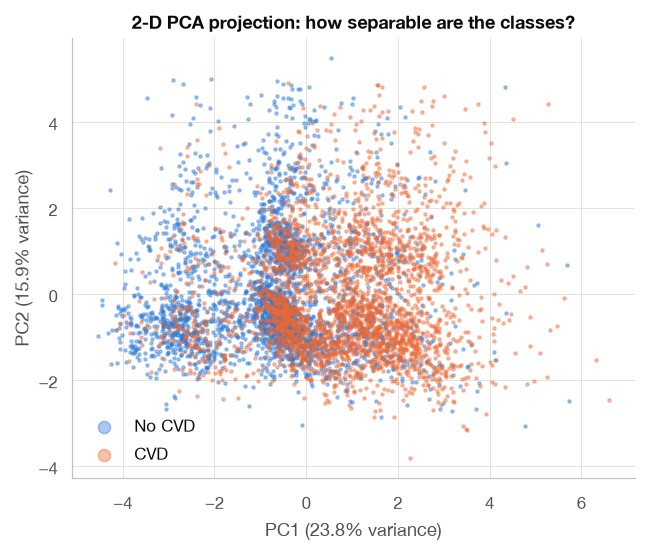

> **Figure 13 — 2-D PCA projection of the clinical features by diagnosis**  
> *What it shows:* PCA summarises all variables in two axes that keep as much variation as possible.  
> *How to read it:* If the colours form separate clouds, the classes are easy to separate; if they mix, the problem is hard.

In [4]:
wf.explore()

## 4. Train / test split
A stratified 80 / 20 split with a fixed seed. The test set is not used again until section 7.

In [5]:
wf.split()
print('Model inputs:', wf.features)

[clinical] Stratified train/test split: 67,772 -> 54,217 rows. train 54,217 / test 13,555 (20% held out, seed 42)
Model inputs: ['age_years', 'gender', 'height', 'bmi', 'ap_hi', 'ap_lo', 'bp_stage', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']


## 5. Hyperparameter tuning of the four base models
A randomized search with 3-fold CV on a stratified 12,000-row subsample of the training set.

In [6]:
wf.tune()
pd.Series({m.name: m.params for m in wf.models})

Tuning Logistic Regression ...


Tuning K-Nearest Neighbors ...


Tuning Random Forest ...


Tuning Support Vector Machine ...


Logistic Regression                       {'clf__C': 0.0019517224641449498}
K-Nearest Neighbors       {'clf__weights': 'uniform', 'clf__p': 2, 'clf_...
Random Forest             {'min_samples_leaf': 10, 'max_features': 0.5, ...
Support Vector Machine    {'clf__C': 0.13066739238053282, 'clf__gamma': ...
dtype: object

## 6. Training: four independent models that reach one answer (stacking)

Each base model (LR, KNN, RF, SVM) is trained **on its own**. The models "communicate" through a
**meta-model** that receives their four probabilities and returns a single answer:

$$\hat P(\mathbf{x}) = \sigma\big(\beta_0 + \beta_1 p_{LR} + \beta_2 p_{KNN} + \beta_3 p_{RF} + \beta_4 p_{SVM}\big)$$

To keep the meta-model honest, it learns from **out-of-fold** probabilities (5-fold CV): every row
is scored by base models that never saw it. The coefficients $\beta_k$ show how much the system
trusts each model. The full derivation is in `docs/mathematical_model.md`, section 5.

In [7]:
wf.train()
wf.ensemble.weights()

Training level-0 models with out-of-fold predictions, then the meta-model ...
  Logistic Regression: OOF + final fit done in 0.1s


  K-Nearest Neighbors: OOF + final fit done in 11.1s


  Random Forest: OOF + final fit done in 5.4s


  Support Vector Machine: OOF + final fit done in 68.4s


{'intercept': -2.7160381860881513,
 'LR': 1.2528686567635454,
 'KNN': 0.7796103349404183,
 'RF': 1.970432764623543,
 'SVM': 1.549723611382434}

## 7. Evaluation on the held-out test set

Here the stacking ensemble is compared with each base model and with two simpler ways of
combining them (hard and soft voting). The metrics are accuracy, precision, recall, specificity,
F1, ROC-AUC, MCC and Brier score. The cell also reports a 95 % bootstrap confidence interval,
a McNemar test against the best base model, and the **referral rule**: a case whose final
probability falls in 0.35–0.65, or where the models split 2–2, goes to a clinician.

{
  "stacking_accuracy": 0.7251198819623755,
  "accuracy_95ci_low": 0.7180357801549243,
  "accuracy_95ci_high": 0.7326466248616748,
  "best_base_model": "Logistic Regression",
  "mcnemar_vs_best_base_p": 0.3290248700456766,
  "referral_rate": 0.24898561416451495,
  "accuracy_on_non_referred": 0.7830058939096267,
  "meets_95_target": false
}


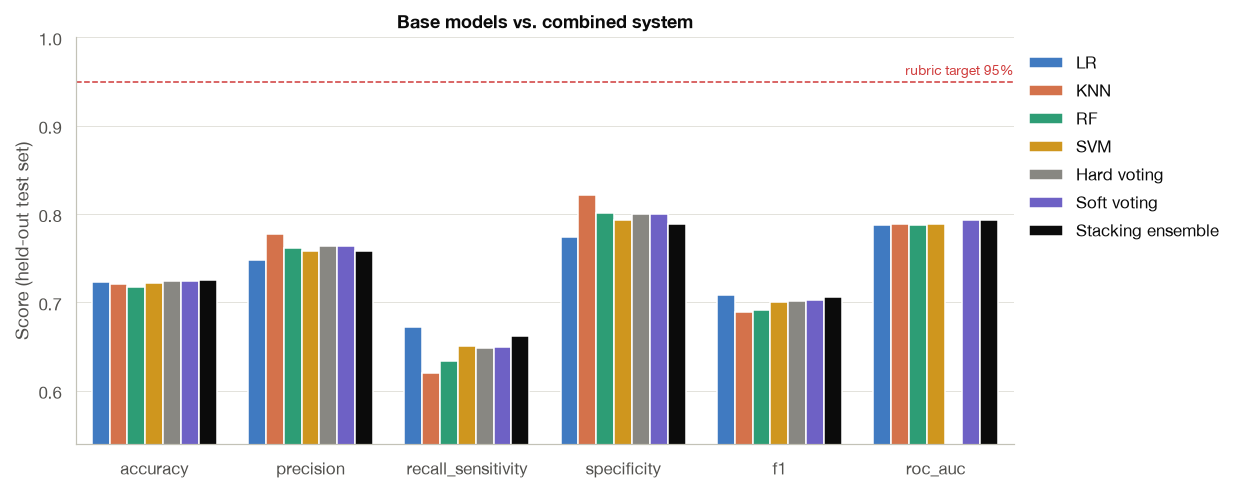

> **Figure 14 — Test-set metrics of the four base models, voting schemes and the stacking ensemble**  
> *What it shows:* Accuracy, precision, sensitivity, specificity, F1 and AUC on data the models never saw.  
> *How to read it:* Higher is better. Compare the combined system (stacking) with the 4 models; the red line is the 95 % target.

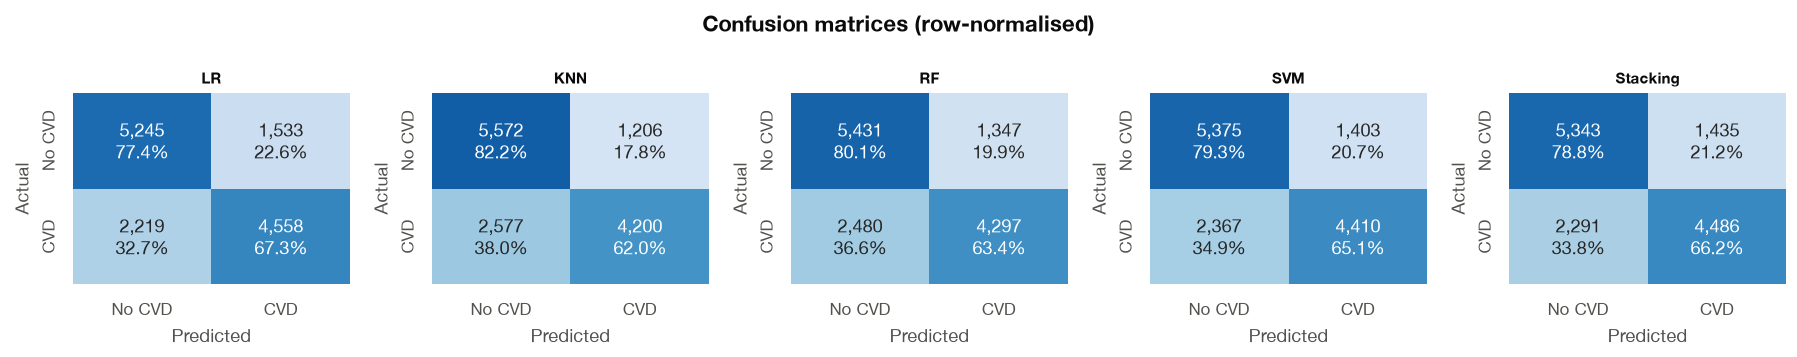

> **Figure 15 — Confusion matrices on the held-out test set**  
> *What it shows:* 2×2 table per model: rows = truth, columns = prediction. Each row adds up to 100 %.  
> *How to read it:* The diagonal holds the hits. The bottom-left cell is the sick cases the model missed: the most dangerous error.

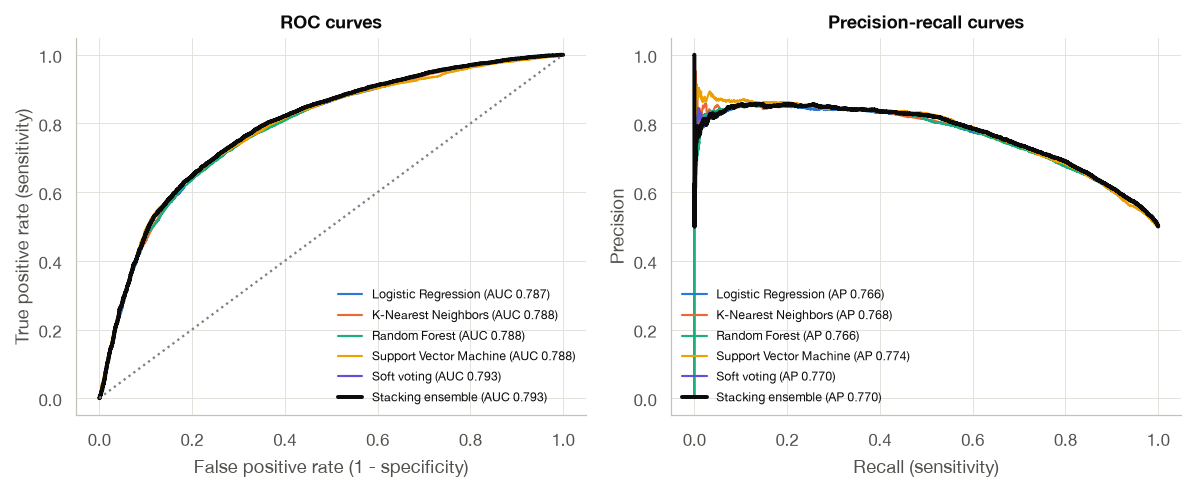

> **Figure 16 — ROC and precision-recall curves**  
> *What it shows:* How hits and false alarms change as the decision threshold moves. The area under the curve (AUC) sums it up.  
> *How to read it:* A curve hugging the top-left (ROC) or top-right (PR) corner is better. The dotted diagonal is chance (AUC 0.5).

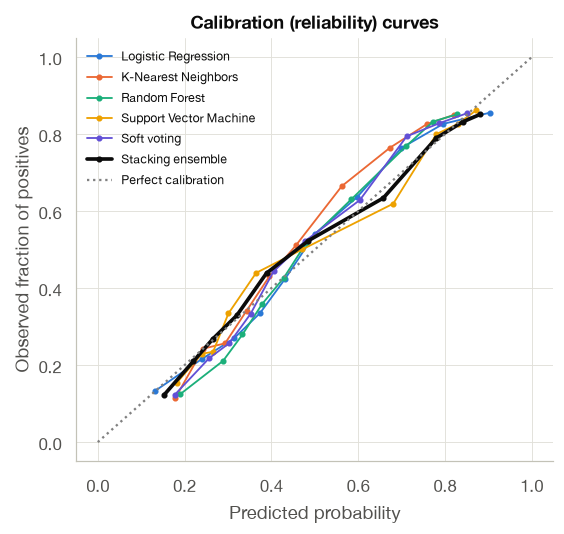

> **Figure 17 — Reliability of the predicted probabilities**  
> *What it shows:* Cases are grouped by predicted probability and compared with the real share of positives.  
> *How to read it:* On the diagonal, '70 %' really means 7 out of 10 such cases are positive. Below it, the model over-estimates.

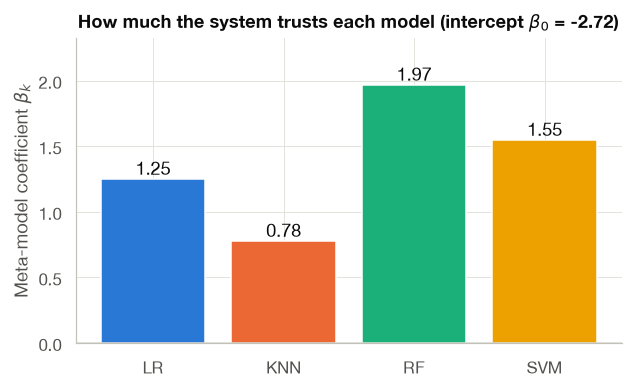

> **Figure 18 — Coefficients learned by the meta-model for each base model**  
> *What it shows:* Weights β learned by the meta-model: P = σ(β₀ + Σ βₖ·pₖ). They are ≥ 0 by design.  
> *How to read it:* Taller bar = the final answer listens more to that model. A weight of 0 means the others already carry its information.

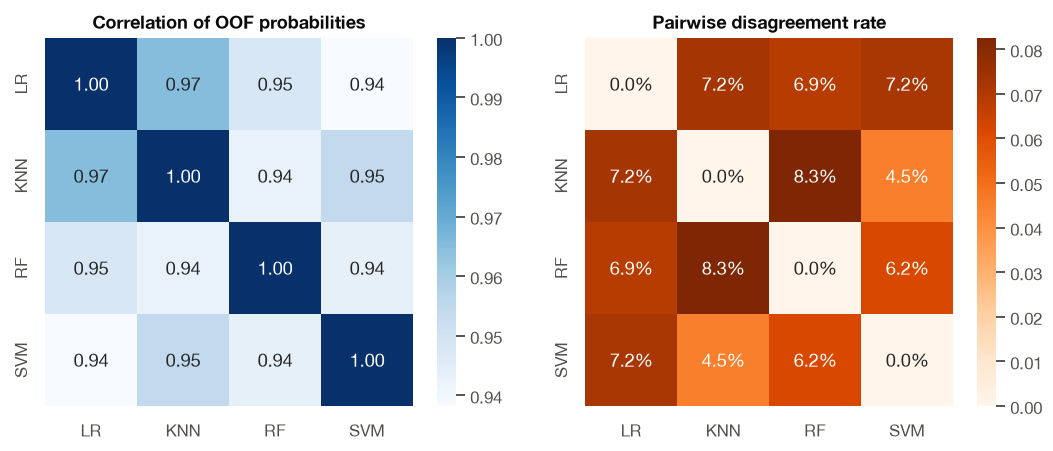

> **Figure 19 — Diversity between base models (OOF correlation and disagreement)**  
> *What it shows:* Left: correlation between the probabilities of each pair of models. Right: % of cases where they disagree.  
> *How to read it:* Combining models only helps if they sometimes disagree: correlations below 1 and non-zero disagreement mean complementary models.

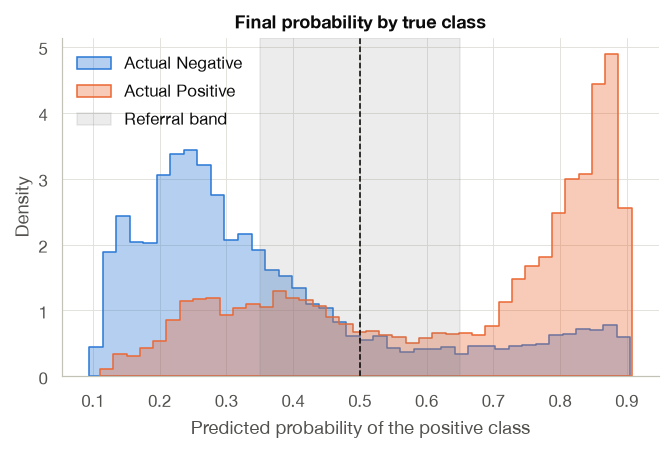

> **Figure 20 — Distribution of the final probability per true class and referral band**  
> *What it shows:* Histogram of the system's probability, one colour per true class. The grey band is the doubt zone.  
> *How to read it:* Ideal: one colour near 0 and the other near 1. Errors live where colours overlap; cases in the grey band go to a clinician.

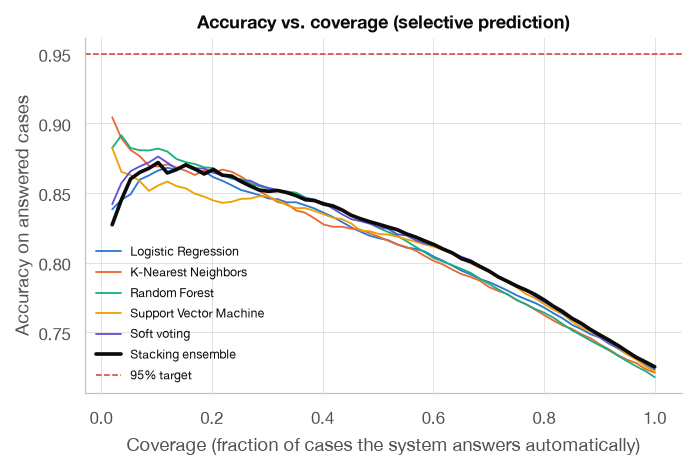

> **Figure 21 — Accuracy when the system answers only its most confident cases**  
> *What it shows:* Cases are sorted from most to least confident; for each share answered (coverage) the accuracy is computed.  
> *How to read it:* Towards the left the system answers fewer cases and gets more right. Where the curve crosses the 95 % line tells which share of cases it can solve on its own at that accuracy.

,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,mcc
Logistic Regression,0.7232,0.7483,0.6726,0.7738,0.7084,0.7875,0.4487
K-Nearest Neighbors,0.7209,0.7769,0.6197,0.8221,0.6895,0.7883,0.4511
Random Forest,0.7177,0.7613,0.6341,0.8013,0.6919,0.7880,0.4415
Support Vector Machine,0.7219,0.7586,0.6507,0.7930,0.7006,0.7881,0.4483
Hard voting,0.7239,0.7638,0.6484,0.7995,0.7014,NaN,0.4531
Soft voting,0.7247,0.7643,0.6497,0.7996,0.7023,0.7931,0.4545
Stacking ensemble,0.7251,0.7576,0.6619,0.7883,0.7066,0.7931,0.4539


In [8]:
wf.evaluate()
wf.results['test_metrics'][['accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc', 'mcc']].round(4)

## 8. Explainability and clinical plausibility
Permutation importance of the whole ensemble, the standardised logistic-regression coefficients (direction of each risk factor) and a **plausibility audit**: for 400 test patients each factor is swept over its range, and the audit counts how often the risk moves the wrong way (for example, less risk with higher blood pressure). The logistic regression and the random forest are constrained to respect the clinical direction of every risk factor, and the meta-model weights are non-negative (`docs/mathematical_model.md`, section 5b).

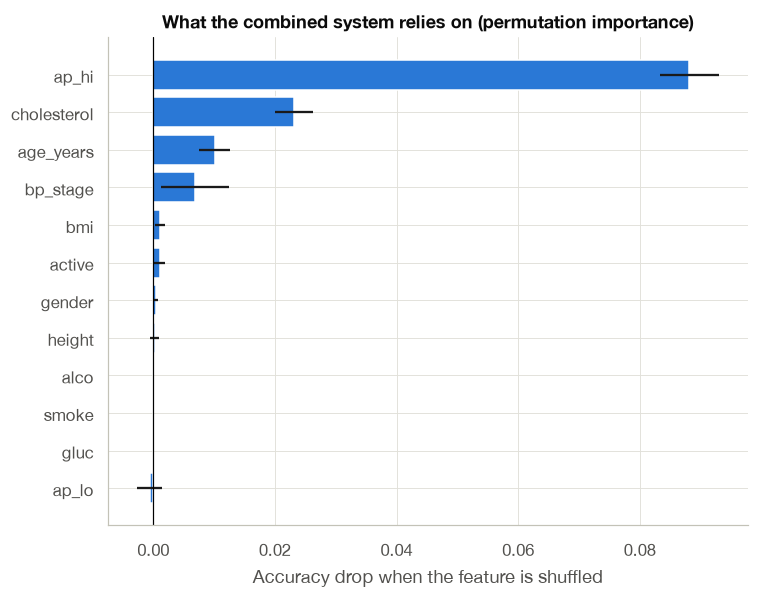

> **Figure 22 — Permutation importance of each feature group for the ensemble**  
> *What it shows:* Permutation importance: how much accuracy drops when one input is randomly shuffled.  
> *How to read it:* Longer bar = the system depends more on that input. Bars near 0 = it could be removed without losing accuracy.

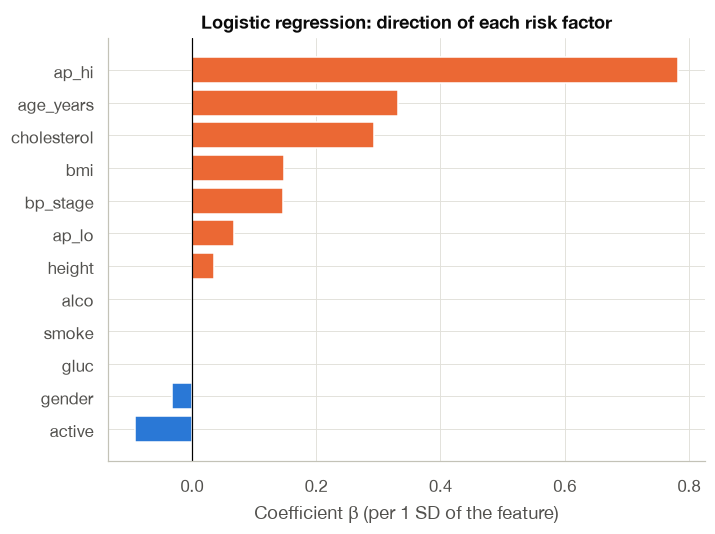

> **Figure 23 — Standardised logistic-regression coefficients**  
> *What it shows:* Logistic-regression coefficients per standard deviation of each input (constrained to the clinical sign).  
> *How to read it:* Orange = raises the risk, blue = lowers it. The longer the bar, the stronger the effect.

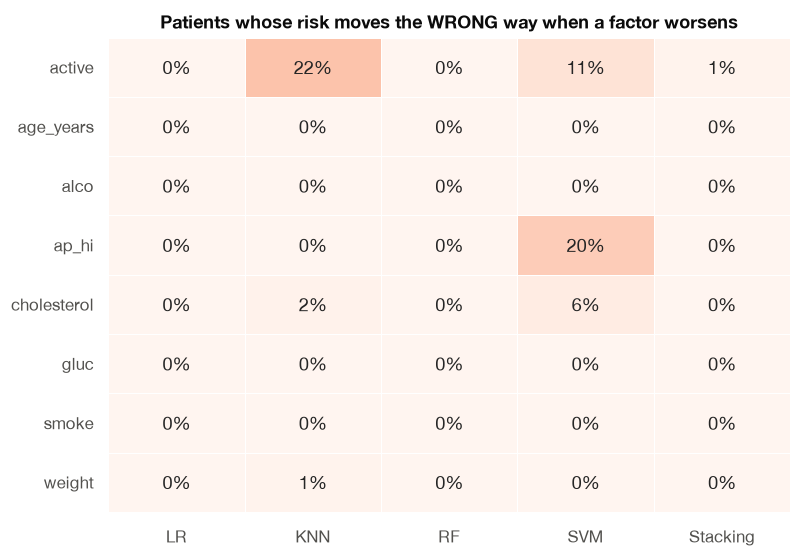

> **Figure 24 — Clinical plausibility audit: wrong-way changes per model and factor**  
> *What it shows:* For real patients one factor (pressure, weight, cholesterol…) is raised with everything else fixed, counting for how many the risk falls by more than 1 point.  
> *How to read it:* 0 % (white) = always consistent with medicine. Red = the model contradicts clinical knowledge. The 'Stacking' column is the final answer.

,feature_group,n_columns,importance,std
4,ap_hi,1,0.088167,0.004789
7,cholesterol,1,0.023083,0.003125
0,age_years,1,0.010083,0.002601
6,bp_stage,1,0.006917,0.005573
3,bmi,1,0.001083,0.000773
11,active,1,0.001083,0.000920
1,gender,1,0.000417,0.000425
2,height,1,0.000250,0.000736
8,gluc,1,0.000000,0.000000
9,smoke,1,0.000000,0.000000


In [9]:
wf.explain()
wf.results['importance']

## 9. Results simulation and risk segmentation

* **K-means risk segmentation** (Hito 1 objective): PCA + K-means (k = 3), with segments named Low / Medium / High by observed prevalence.
* **Simulation:** 8 hypothetical patient archetypes and 12 unseen test patients go through the 4 models and the meta-model. The full trace of each case is saved in `tables/*_trace.json`.

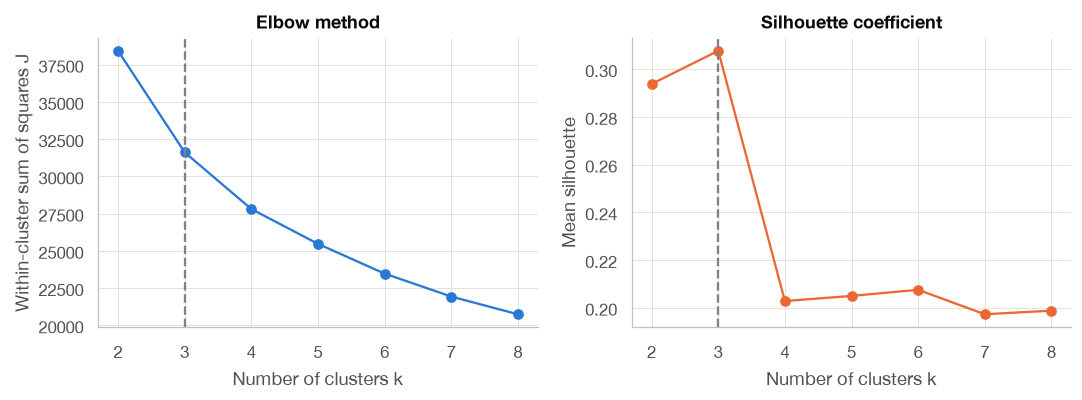

> **Figure 25 — Choice of k for K-means (k = 3 chosen)**  
> *What it shows:* Elbow method (inertia J) and silhouette coefficient for k = 2…8 groups.  
> *How to read it:* Look for the 'elbow' where J stops falling fast and a high silhouette. k = 3 was chosen (low, medium, high risk).

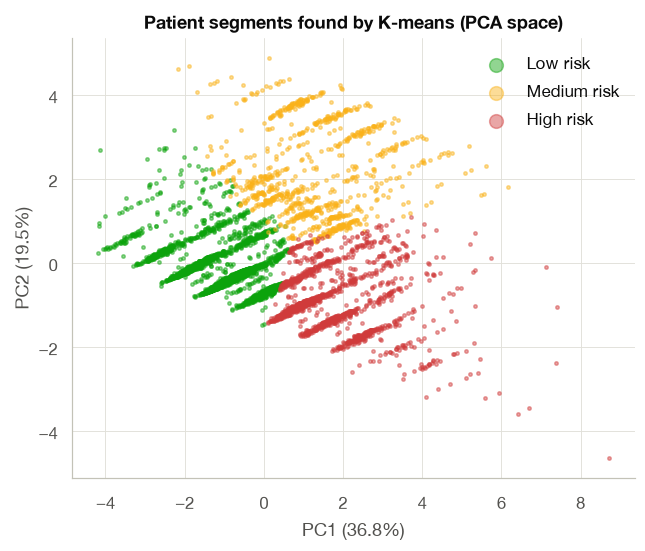

> **Figure 26 — Risk segments in PCA space (test set)**  
> *What it shows:* Test patients coloured by the group K-means gave them (without using the diagnosis).  
> *How to read it:* Each colour is a similar patient profile; the groups occupy different areas of the map.

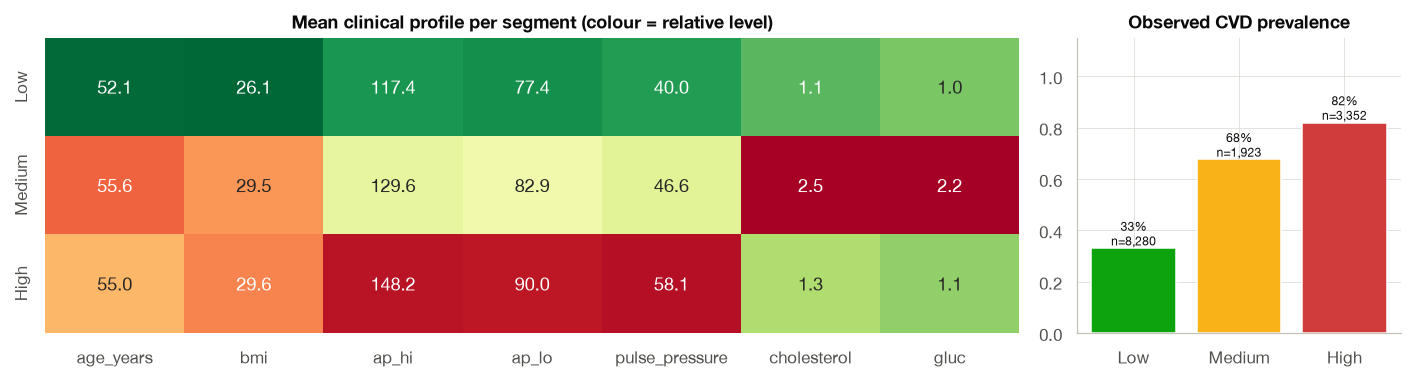

> **Figure 27 — Mean profile and observed CVD prevalence per segment (test set)**  
> *What it shows:* Left: mean of each variable per group. Right: real share with CVD in each group.  
> *How to read it:* The high-risk group should be older, with higher pressure and more disease. It confirms the groups make clinical sense.

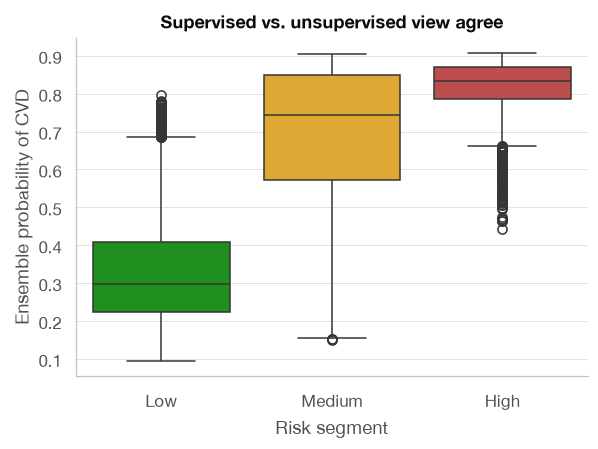

> **Figure 28 — Ensemble probability distribution inside each K-means segment**  
> *What it shows:* Probability given by the supervised system inside each unsupervised group.  
> *How to read it:* Boxes should rise from low to high: two independent methods reach the same conclusion.

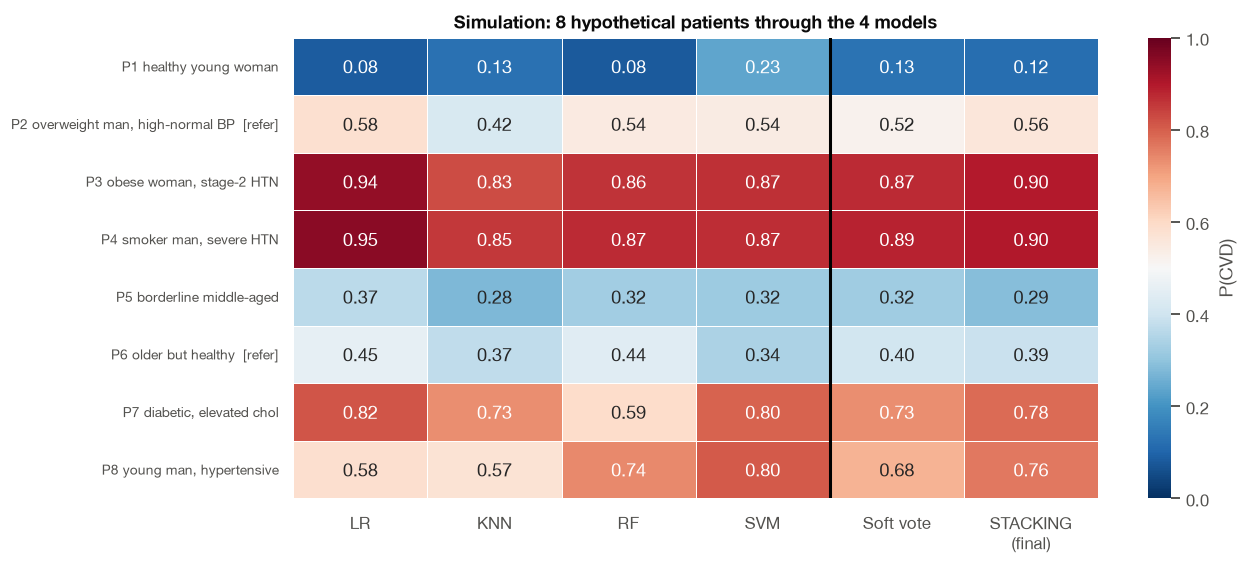

> **Figure 29 — Per-model and final probability for simulated patient archetypes**  
> *What it shows:* Each row is an invented patient; each column the probability from each model and, last, the single answer.  
> *How to read it:* Blue = low risk, red = high. Follow case by case how the 4 models combine into 1 answer. '[refer]' = sent to a clinician.

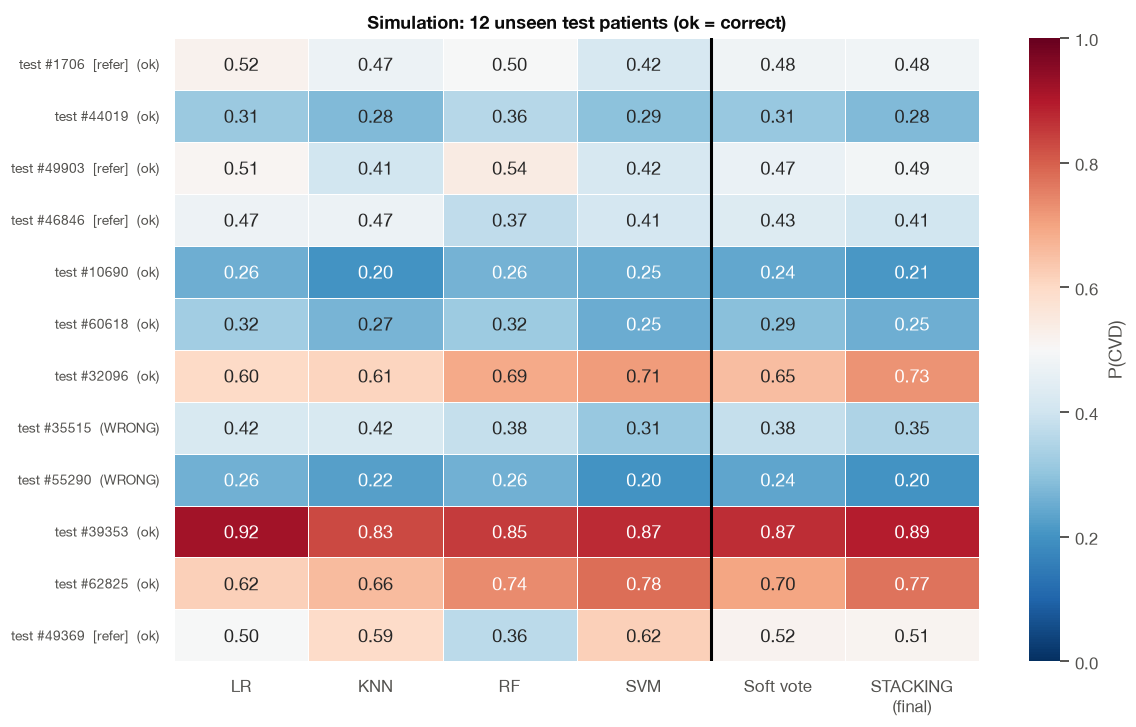

> **Figure 30 — Per-model and final probability for 12 unseen test patients**  
> *What it shows:* Same as above with real test-set patients and their true diagnosis.  
> *How to read it:* '(ok)' = the system was right, '(WRONG)' = it was wrong. It is the full trace of each prediction.

,case,LR,KNN,RF,SVM,soft_vote,final_probability,final_prediction,models_agreeing,referred_to_clinician,risk_segment
0,P1 healthy young woman,0.084279,0.1260,0.079875,0.234901,0.131264,0.120173,0,4,False,Low
1,"P2 overweight man, high-normal BP",0.578223,0.4212,0.543730,0.541300,0.521113,0.561443,1,3,True,Low
2,"P3 obese woman, stage-2 HTN",0.940046,0.8272,0.862741,0.866075,0.874016,0.895553,1,4,False,Medium
3,"P4 smoker man, severe HTN",0.952819,0.8532,0.872039,0.867260,0.886329,0.900715,1,4,False,High
4,P5 borderline middle-aged,0.366965,0.2768,0.324291,0.318692,0.321687,0.287491,0,4,False,Low
5,P6 older but healthy,0.454633,0.3748,0.438886,0.343556,0.402969,0.387690,0,4,True,Low
6,"P7 diabetic, elevated chol",0.815080,0.7340,0.590653,0.795717,0.733863,0.781490,1,4,False,Medium
7,"P8 young man, hypertensive",0.583430,0.5716,0.740623,0.804834,0.675122,0.762632,1,4,False,High


In [10]:
wf.simulate()
wf.results['simulation']

## 10. Export and traceability report

In [11]:
wf.export()
path = wf.tracker.finalize()
print(open(wf.tracker.root / 'TRACEABILITY.md').read()[:3000])

# Traceability report — clinical tier

Run: 2026-10-27T09:30:16 → 2026-10-27T09:34:34 · seed 42 · Python 3.14.7 · scikit-learn 1.9.1

## Inputs

| File | Description | SHA-256 |
|---|---|---|
| `data/raw/cardio_train.csv` | Kaggle Cardiovascular Disease dataset (S. Ulianova, 2019) | `21a705d23381b0df…` |

## Data lineage

| # | Step | Rows before | Rows after | Removed | Detail |
|---|---|---|---|---|---|
| 1 | Load raw CSV | 70,000 | 70,000 | 0 | 13 columns, separator ';' |
| 2 | Drop identifier columns | 70,000 | 70,000 | 0 | dropped ['id'] (no predictive meaning) |
| 3 | Remove duplicated records | 70,000 | 69,976 | 24 | identical rows (all features and label) kept once |
| 4 | Remove contradictory records | 69,976 | 69,942 | 34 | same feature values with different diagnosis |
| 5 | Filter impossible blood pressure | 69,942 | 68,688 | 1,254 | ap_hi outside [80, 250]: 247; ap_lo outside [40, 160]: 1007 |
| 6 | Check systolic > diastolic | 68,688 | 68,606 | 82 | systolic pressure must